# Лестница базовых моделей: E01–E05

Сравнение лучших вариантов каждой семьи на трёх локальных протоколах валидации:

- **9010** — chronological 90/10, основной temporal-протокол;
- **last10** — последние 10 событий пользователя (robustness-проверка);
- **masked10** — случайная маска 10% историй, competition-mimic диагностика
  (гипотеза о замаскированных взаимодействиях, `notes/data.md` раздел 7).

Числа — `results/*.json`, которые пишут скрипты `scripts/e0*.py`; ноутбук
перечитывает их при каждом запуске, поэтому после E05 достаточно перезапустить.
Журнал гипотез и выводы: `notes/hypotheses.md`.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "src" / "recsys").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

EXPERIMENTS = {
    "e01_e02_popularity": {"E01_count": "E01 popularity (count)"},
    "e03_knn": {"binary_cosine": "E03 ItemKNN (binary cosine)"},
    "e04_als": {"als_rating": "E04 ALS (rating weights)"},
    "e04b_als_ease": {"ease_l1500": "E04b EASE (λ=1500)"},
    "e05_sasrec": {"sasrec_default": "E05 SASRec (e64/len100/15эп)"},
    "e05c_sasrec_sweep": {"e128_len150_ep40": "E05c SASRec (e128/len150/40эп)"},
    "e07_reranker": {"catboost_rerank": "E07 CatBoost rerank"},
}

rows = []
for file, variants in EXPERIMENTS.items():
    path = ROOT / "results" / f"{file}.json"
    if not path.is_file():
        continue
    results = json.loads(path.read_text())
    # e05c пишёт панели сразу по конфигам (только сплит 9010) — приводим к общему виду
    if file == "e05c_sasrec_sweep":
        results = {"results": {"9010": results["results"]}}
    for split, split_variants in results["results"].items():
        for variant, label in variants.items():
            if variant in split_variants:
                panel = split_variants[variant]
                rows.append({
                    "модель": label,
                    "протокол": split,
                    "recall@10 macro": round(panel["recall@10_macro_relevant"], 4),
                    "recall@10 capped": round(panel["recall@10_macro_capped"], 4),
                    "recall@10 /10": round(panel["recall@10_macro_k"], 4),
                    "recall@10 micro": round(panel["recall@10_micro"], 4),
                })
df = pd.DataFrame(rows)
pivot = df.pivot(index="модель", columns="протокол", values="recall@10 macro")
pivot = pivot[["9010", "last10", "masked10"]].sort_values("9010", ascending=False)
pivot

протокол,9010,last10,masked10
модель,,,
E07 CatBoost rerank,0.1949,NaN,NaN
E05c SASRec (e128/len150/40эп),0.1875,NaN,NaN
E05 SASRec (e64/len100/15эп),0.1602,NaN,0.0642
E04b EASE (λ=1500),0.0716,NaN,0.1758
E04 ALS (rating weights),0.0658,0.0603,0.1691
E03 ItemKNN (binary cosine),0.0604,0.0584,0.1222
E01 popularity (count),0.0367,0.0383,0.0667


Лучший вариант каждой семьи (полные панели всех вариантов — в JSON):

- **macro** — среднее по пользователям от `hits / |ground truth|` (основной вариант до сверки с Kaggle);
- **capped** — делитель `min(10, |gt|)`; **/10** — делитель 10; **micro** — сумма хитов / сумма релевантных.

Панель нужна, чтобы по скорам первых сабмитов E01/E03/E04 определить фактическую
формулу Kaggle и протокол скрытого теста: совпадение до 4 знаков двух разных
сабмитов с одним из вариантов однозначно его идентифицирует.

In [2]:
df.sort_values(["протокол", "recall@10 macro"], ascending=[True, False]).style.hide(axis="index")

модель,протокол,recall@10 macro,recall@10 capped,recall@10 /10,recall@10 micro
E07 CatBoost rerank,9010,0.194900,0.248600,0.170000,0.111400
E05c SASRec (e128/len150/40эп),9010,0.187500,0.236700,0.159900,0.104800
E05 SASRec (e64/len100/15эп),9010,0.160200,0.203900,0.139000,0.091100
E04b EASE (λ=1500),9010,0.071600,0.086200,0.051100,0.033500
E04 ALS (rating weights),9010,0.065800,0.080400,0.048400,0.031800
E03 ItemKNN (binary cosine),9010,0.060400,0.078100,0.052500,0.034400
E01 popularity (count),9010,0.036700,0.054700,0.042600,0.027900
E04 ALS (rating weights),last10,0.060300,0.060300,0.060300,0.060300
E03 ItemKNN (binary cosine),last10,0.058400,0.058400,0.058400,0.058400
E01 popularity (count),last10,0.038300,0.038300,0.038300,0.038300


## Сравнение протоколов

Один и тот же сабмит-кандидат даёт заметно разные числа на трёх протоколах:
персонализированные модели на masked10 почти вдвое выше, чем на отрезанном
хвосте 9010 — случайная маска оставляет в train более плотную картину
предпочтений. Какой протокол ближе к скрытому тесту — покажут скоры Kaggle.

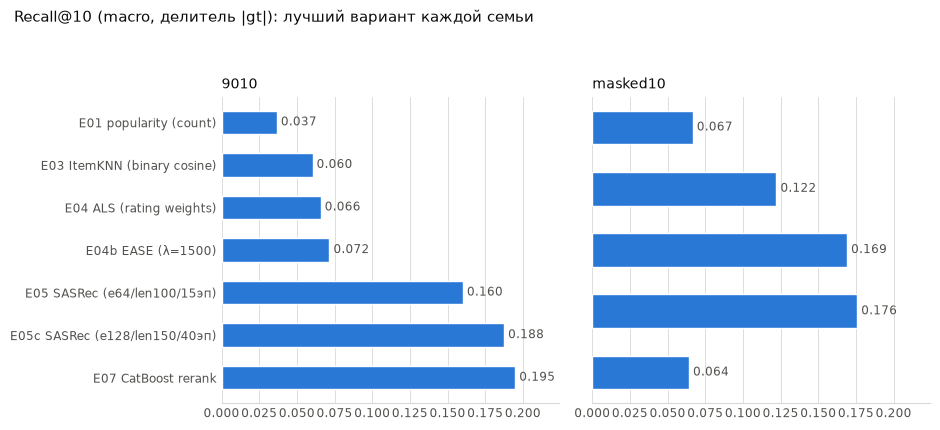

In [3]:
import matplotlib.pyplot as plt

# единая шкала X для честного сравнения панелей
import numpy as np
xmax = float(np.nanmax(pivot.values)) * 1.15  # не у всех семей есть все протоколы

# палитра: один оттенок — идентичность моделей на оси Y, цвет ничего не кодирует
BAR = "#2a78d6"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#d9d8d4"

panels = ["9010", "masked10"]
fig, axes = plt.subplots(1, len(panels), figsize=(9.5, 0.42 * len(pivot) + 1.4), sharex=True)
for ax, split in zip(axes, panels):
    values = pivot[split].dropna()
    y = range(len(values))
    ax.barh(y, values.values, height=0.55, color=BAR, edgecolor="white", linewidth=1)
    ax.set_yticks(list(y), values.index if ax is axes[0] else ["" for _ in y])
    for yi, value in zip(y, values.values):
        ax.text(value + xmax * 0.012, yi, f"{value:.3f}", va="center", ha="left", fontsize=8.5, color=INK_2)
    ax.set_title(f"{split}", fontsize=10, color=INK, loc="left")
    ax.set_xlim(0, xmax)
    ax.tick_params(colors=INK_2, labelsize=8.5, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.xaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
fig.suptitle("Recall@10 (macro, делитель |gt|): лучший вариант каждой семьи", x=0.02, ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

## Выводы (обновляются по мере экспериментов)

1. **Персонализация работает**: ItemKNN ≈ ×1.7 к popularity, ALS ещё выше.
2. **Rating-сигнал**: на агрегатах (E02) и попарных сходствах (E03) бесполезен,
   но в латентной модели ALS даёт небольшой устойчивый плюс.
3. **Протоколы расходятся вдвое** — до сверки с Kaggle нельзя выбирать модель
   по одному сплиту; выбор лучших вариантов зафиксирован на основном 9010.
4. Порядок семей одинаков на всех трёх протоколах — лестница устойчива
   к способу разбиения, различия только в абсолютных значениях.